# Bilan carbone marbec-gpu et marbec-data

Serveurs du DEN hébergés au CINES et allumés en continu : toute leur consommation est comptée, repos compris.

- énergie (kWh) = puissance (W) × heures / 1000 × PUE
- émissions (kgCO2e) = énergie × facteur d'émission de l'électricité

Données : jobs SLURM (`sacct`, depuis le 26/11/2025) et relevés de puissance toutes les 5 min (`/var/log/bilan-carbone/`).

## Paramètres

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DOSSIER = Path("donnees-marbec-gpu-2025-11-26_2026-11-26")
SACCT = DOSSIER / "sacct_2025-11-26_2026-11-26.csv"
PUISSANCE_TXT = DOSSIER / "puissance.txt"
SERVEUR_LOG = Path("/var/log/bilan-carbone/serveur_power.csv")
GPU_LOG = Path("/var/log/bilan-carbone/gpu_power.csv")

PUE = 1.22          # CINES, rapport d'activité 2025
FE_ELEC = 0.0461    # kgCO2e/kWh, ADEME Base Empreinte, électricité 2025, mix moyen
PUISSANCE_RETENUE = "moyenne"   # ou "max"

N_COEURS = 80       # 2 x Xeon Platinum 8380
TDP_CPU_W = 2 * 270
N_GPU = 3           # 3 x A40
P_GPU_MAX_W = 300
P_GPU_REPOS_W = 22
CHARGE_GPU = 0.7    # remplacée par la mesure s'il y a assez de relevés
MIN_RELEVES_GPU = 100
MIN_JOURS_REGRESSION = 14
HEURES_CPU = "reelles"   # ou "reservees"

ANONYMISER = True
COMPTES_TECHNIQUES = ["din_admin", "test", "test_din", "testclaudia", "barriertest"]
CORRESPONDANCE = Path.home() / "GPU_marbec-green/correspondance_utilisateurs_PRIVE.csv"   # ne pas partager

PERIODES = {
    "nov-dec 2025": ("2025-11-26", "2026-01-01"),
    "jan-nov 2026": ("2026-01-01", "2026-11-26"),
}

## Puissance du serveur

Relevés `ipmitool` du serveur complet ; à défaut, la lecture ponctuelle de `puissance.txt`.

In [2]:
if SERVEUR_LOG.exists():
    srv = pd.read_csv(SERVEUR_LOG, header=None, names=["ts", "w"], parse_dates=["ts"])
    p_moy, p_max = srv.w.mean(), srv.w.max()
    P_SERVEUR = p_max if PUISSANCE_RETENUE == "max" else p_moy
    print(f"{len(srv)} relevés du {srv.ts.min():%d/%m %H:%M} au {srv.ts.max():%d/%m %H:%M}")
    print(f"moyenne {p_moy:.0f} W, min {srv.w.min():.0f} W, max {p_max:.0f} W")
else:
    txt = PUISSANCE_TXT.read_text()
    P_SERVEUR = float(re.search(r"Average power reading.*?(\d+) Watts", txt).group(1))
    print("lecture ponctuelle puissance.txt")

print(f"Puissance retenue ({PUISSANCE_RETENUE}) : {P_SERVEUR:.0f} W")

2045 relevés du 18/11 03:09 au 25/11 05:10
moyenne 922 W, min 487 W, max 1759 W
Puissance retenue (moyenne) : 922 W


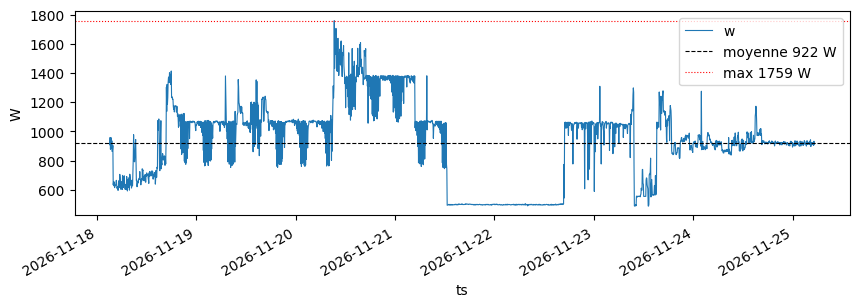

In [3]:
if SERVEUR_LOG.exists():
    ax = srv.set_index("ts").w.plot(figsize=(10, 3), lw=0.8)
    ax.axhline(p_moy, color="k", ls="--", lw=0.8, label=f"moyenne {p_moy:.0f} W")
    ax.axhline(p_max, color="r", ls=":", lw=0.8, label=f"max {p_max:.0f} W")
    ax.set_ylabel("W")
    ax.legend()
    plt.show()

In [4]:
if GPU_LOG.exists():
    gpu = pd.read_csv(GPU_LOG, header=None, names=["ts", "gpu", "w", "util", "mem"])
    for c in ["w", "util", "mem"]:
        gpu[c] = pd.to_numeric(gpu[c], errors="coerce")
    ignorees = gpu.w.isna().sum()
    gpu = gpu.dropna(subset=["w"]).astype({"gpu": int})
    display(gpu.groupby("gpu")[["w", "util"]].mean().round(1))
    p_gpu = gpu.groupby("ts").w.sum().mean()
    print(f"GPU : {p_gpu:.0f} W en moyenne, soit {100 * p_gpu / P_SERVEUR:.0f} % du serveur")
    if ignorees:
        print(f"{ignorees} lignes ignorées (nvidia-smi n'a pas trouvé les GPU)")

,w,util
gpu,,
0,211.5,68.4
1,36.4,2.7
2,65.2,13.8


GPU : 313 W en moyenne, soit 34 % du serveur
4 lignes ignorées (nvidia-smi n'a pas trouvé les GPU)


In [5]:
if GPU_LOG.exists():
    occupee = gpu.mem.gt(100) | (gpu.mem.isna() & gpu.w.gt(P_GPU_REPOS_W + 15))
    charge = ((gpu.w[occupee] - P_GPU_REPOS_W) / (P_GPU_MAX_W - P_GPU_REPOS_W)).clip(0, 1)
    print(f"charge mesurée : {charge.mean():.2f} sur {occupee.sum()} relevés de GPU occupée")
    if occupee.sum() >= MIN_RELEVES_GPU:
        CHARGE_GPU = round(charge.mean(), 2)
    else:
        print(f"pas encore assez de relevés, on garde {CHARGE_GPU}")

charge mesurée : 0.80 sur 2265 relevés de GPU occupée


## Bilan annuel

Pour 2025 on applique la puissance mesurée en novembre 2026. L'usage était plus faible en 2025 (pas encore de partition gpu) : ce chiffre est probablement un peu surestimé.

In [6]:
def emissions(p_w, heures):
    kwh = p_w * heures / 1000 * PUE
    return kwh, kwh * FE_ELEC

fin_2026 = pd.Timestamp(PERIODES["jan-nov 2026"][1])
HEURES = {
    "2025": 8760,
    f"2026 (jusqu'au {fin_2026 - pd.Timedelta(days=1):%d/%m})": (fin_2026 - pd.Timestamp("2026-01-01")).total_seconds() / 3600,
}

bilan = {}
for annee, h in HEURES.items():
    kwh, kg = emissions(P_SERVEUR, h)
    bilan[("marbec-gpu", annee)] = kg / 1000
    print(f"marbec-gpu {annee} : {h:,.0f} h, {kwh:,.0f} kWh, {kg / 1000:.2f} tCO2e")

marbec-gpu 2025 : 8,760 h, 9,850 kWh, 0.45 tCO2e
marbec-gpu 2026 (jusqu'au 25/11) : 7,896 h, 8,879 kWh, 0.41 tCO2e


## Jobs SLURM

In [7]:
def en_heures(txt):
    m = re.match(r"(?:(\d+)-)?(?:(\d+):)?(\d+):(\d+(?:\.\d+)?)$", str(txt))
    if not m:
        return 0.0
    j, h, mi, se = (float(x) if x else 0.0 for x in m.groups())
    return j * 24 + h + mi / 60 + se / 3600

def nb_gpu(tres):
    m = re.search(r"gres/gpu(?::[^=,]+)?=(\d+)", str(tres))
    return int(m.group(1)) if m else 0

jobs = pd.read_csv(SACCT, sep="|", dtype=str)
jobs = jobs[jobs.User.fillna("") != ""].copy()
for c in ["ElapsedRaw", "AllocCPUS", "CPUTimeRAW"]:
    jobs[c] = pd.to_numeric(jobs[c], errors="coerce").fillna(0)
jobs["Start"] = pd.to_datetime(jobs.Start, errors="coerce")
jobs["End"] = pd.to_datetime(jobs.End, errors="coerce")
jobs["n_gpu"] = jobs.AllocTRES.map(nb_gpu)
jobs.loc[(jobs.Partition == "gpu") & (jobs.n_gpu == 0) & (jobs.ElapsedRaw > 0), "n_gpu"] = 1
jobs["etat"] = jobs.State.str.split().str[0]
jobs["cpu_reel_h"] = jobs.TotalCPU.map(en_heures)
if "JobName" in jobs:
    jobs["type"] = np.where(jobs.JobName.str.startswith("spawner"), "JupyterHub", "batch")

print(f"{len(jobs)} jobs du {jobs.Start.min():%d/%m/%Y} au {jobs.Start.max():%d/%m/%Y}")
avec_cpu = jobs[jobs.ElapsedRaw > 60].groupby(jobs.Start.dt.to_period("M")).cpu_reel_h.apply(lambda x: (x > 0).mean())
print("part des jobs avec TotalCPU renseigné, par mois :")
print((100 * avec_cpu).round(0).to_string())

11121 jobs du 26/11/2025 au 25/11/2026
part des jobs avec TotalCPU renseigné, par mois :
Start
2025-11    100.0
2025-12    100.0
2026-01    100.0
2026-02    100.0
2026-03    100.0
2026-04    100.0
2026-05    100.0
2026-06    100.0
2026-07    100.0
2026-08    100.0
2026-09    100.0
2026-10    100.0
2026-11     99.0
Freq: M


## Anonymisation

Logins remplacés par `user01`, `user02`... La correspondance est gardée hors du dépôt et réutilisée à chaque exécution : chacun garde son numéro, seuls les nouveaux en reçoivent un.

In [8]:
if ANONYMISER:
    corresp = {}
    if CORRESPONDANCE.exists():
        corresp = pd.read_csv(CORRESPONDANCE, index_col="login", dtype=str)["id"].to_dict()
    nouveaux = sorted(set(jobs.User) - set(corresp) - set(COMPTES_TECHNIQUES))
    n = max((int(v[4:]) for v in corresp.values() if str(v).startswith("user")), default=0)
    for login in pd.Series(nouveaux, dtype=str).sample(frac=1):
        n += 1
        corresp[login] = f"user{n:02d}"
    corresp.update({c: "compte_technique" for c in COMPTES_TECHNIQUES})
    pd.Series(corresp, name="id").rename_axis("login").to_csv(CORRESPONDANCE)

    jobs["User"] = jobs.User.map(corresp).fillna("compte_technique")
    jobs = jobs.drop(columns=["Account", "JobName", "State"], errors="ignore")

cols = [c for c in ["User", "Partition", "Start", "End", "ElapsedRaw", "AllocCPUS",
                    "AllocTRES", "CPUTimeRAW", "cpu_reel_h", "etat", "type"] if c in jobs]
if ANONYMISER:
    jobs[cols].to_csv(SACCT.stem + "_anonyme.csv", sep="|", index=False)
jobs[cols].head()

,User,Partition,Start,End,ElapsedRaw,AllocCPUS,AllocTRES,CPUTimeRAW,cpu_reel_h,etat,type
0,user28,standard,2025-11-26 14:41:58,2025-11-26 14:43:02,64,2,"billing=2,cpu=2,mem=30G,node=1",128,0.008057,CANCELLED,batch
2,user28,standard,2025-11-26 14:43:32,2025-11-26 15:12:30,1738,2,"billing=2,cpu=2,mem=30G,node=1",3476,0.360163,COMPLETED,batch
4,user28,standard,NaT,2025-11-26 14:44:57,0,0,NaN,0,0.000000,CANCELLED,batch
5,user49,standard,2025-11-26 15:17:53,2025-11-26 15:55:00,2227,1,"billing=1,cpu=1,mem=64G,node=1",2227,0.573199,COMPLETED,batch
7,user55,standard,2025-11-26 15:24:16,2025-11-26 15:24:34,18,1,"billing=1,cpu=1,mem=2000M,node=1",18,0.001327,CANCELLED,JupyterHub


## Heures par période

In [9]:
def heures(jobs, debut, fin):
    debut, fin = pd.Timestamp(debut), pd.Timestamp(fin)
    duree = (jobs.End.fillna(fin).clip(upper=fin) - jobs.Start.clip(lower=debut)).dt.total_seconds()
    duree = duree.clip(lower=0).fillna(0)
    part = (duree / jobs.ElapsedRaw.where(jobs.ElapsedRaw > 0)).clip(0, 1).fillna(0)
    d = jobs.assign(h_coeur=jobs.AllocCPUS * duree / 3600, h_gpu=jobs.n_gpu * duree / 3600,
                    h_cpu_reel=jobs.cpu_reel_h * part)
    return d[duree > 0]

for nom, (deb, fin) in PERIODES.items():
    d = heures(jobs, deb, fin)
    h = (pd.Timestamp(fin) - pd.Timestamp(deb)).total_seconds() / 3600
    print(f"{nom} : {d.h_coeur.sum():,.0f} h.coeur réservées ({100 * d.h_coeur.sum() / (N_COEURS * h):.0f} %), "
          f"{d.h_cpu_reel.sum():,.0f} h.coeur utilisées ({100 * d.h_cpu_reel.sum() / (N_COEURS * h):.0f} %), "
          f"{d.h_gpu.sum():,.0f} h.GPU ({100 * d.h_gpu.sum() / (N_GPU * h):.0f} %)")

nov-dec 2025 : 8,440 h.coeur réservées (12 %), 2,222 h.coeur utilisées (3 %), 0 h.GPU (0 %)
jan-nov 2026 : 288,325 h.coeur réservées (46 %), 74,493 h.coeur utilisées (12 %), 6,543 h.GPU (28 %)


## Poids d'une heure GPU et d'une heure coeur

Ils servent à répartir le total entre utilisateurs.

- heure GPU : (300 W - 22 W) × charge moyenne mesurée des GPU occupées
- heure coeur : 70 % du TDP / 80 coeurs ≈ 4,7 W

Avec au moins 14 jours de relevés, une régression de la puissance du serveur sur les GPU et coeurs réservés remplace ces valeurs.

In [10]:
W_GPU = (P_GPU_MAX_W - P_GPU_REPOS_W) * CHARGE_GPU
W_COEUR = TDP_CPU_W * 0.7 / N_COEURS

if SERVEUR_LOG.exists():
    t = pd.to_datetime(srv.ts, utc=True).dt.tz_convert("Europe/Paris").dt.tz_localize(None).values
    fin_jobs = jobs.End.fillna(pd.Timestamp.now())
    j = jobs[(jobs.ElapsedRaw > 0) & (fin_jobs > t.min()) & (jobs.Start < t.max())]
    deb, fin = j.Start.values, j.End.fillna(pd.Timestamp.now()).values
    n_gpu, n_coeur = np.zeros(len(t)), np.zeros(len(t))
    for i in range(0, len(t), 2000):
        actif = (deb <= t[i:i + 2000, None]) & (fin > t[i:i + 2000, None])
        n_gpu[i:i + 2000] = actif @ j.n_gpu.values
        n_coeur[i:i + 2000] = actif @ j.AllocCPUS.values

    jours = (srv.ts.max() - srv.ts.min()).days
    if jours >= MIN_JOURS_REGRESSION:
        X = np.column_stack([np.ones(len(t)), n_gpu, n_coeur])
        coef = np.linalg.lstsq(X, srv.w.values, rcond=None)[0]
        r2 = 1 - ((srv.w.values - X @ coef) ** 2).sum() / ((srv.w.values - srv.w.mean()) ** 2).sum()
        print(f"régression sur {jours} jours, GPU réservées : {sorted(set(n_gpu.astype(int).tolist()))}")
        print(f"base {coef[0]:.0f} W, {coef[1]:.0f} W par GPU, {coef[2]:.1f} W par coeur (R2 = {r2:.2f})")
        if coef[1] > 0:
            W_GPU = coef[1]
        if HEURES_CPU == "reservees" and coef[2] > 0:
            W_COEUR = coef[2]
    else:
        print(f"régression : {jours} jours de relevés sur {MIN_JOURS_REGRESSION} nécessaires, poids par défaut")

print(f"poids utilisés : {W_GPU:.0f} W par heure GPU, {W_COEUR:.1f} W par heure coeur")

régression : 7 jours de relevés sur 14 nécessaires, poids par défaut
poids utilisés : 222 W par heure GPU, 4.7 W par heure coeur


## Répartition par utilisateur

Indicative : le total de chaque période, repos compris, est partagé au prorata des heures GPU et coeur de chacun, pondérées par les poids ci-dessus.

In [11]:
repart = {}
for nom, (deb, fin) in PERIODES.items():
    d = heures(jobs, deb, fin)
    h = (pd.Timestamp(fin) - pd.Timestamp(deb)).total_seconds() / 3600
    kwh, kg = emissions(P_SERVEUR, h)
    u = d.groupby("User")[["h_coeur", "h_cpu_reel", "h_gpu"]].sum()
    h_cpu = u.h_cpu_reel if HEURES_CPU == "reelles" else u.h_coeur
    poids = u.h_gpu * W_GPU + h_cpu * W_COEUR
    u["part_%"] = 100 * poids / poids.sum()
    u["kgCO2e"] = u["part_%"] / 100 * kg
    repart[nom] = u.sort_values("kgCO2e", ascending=False)
    print(f"{nom} : {kwh:,.0f} kWh, {kg:,.0f} kgCO2e")
    display(repart[nom].head(10).round(1))

nov-dec 2025 : 972 kWh, 45 kgCO2e


,h_coeur,h_cpu_reel,h_gpu,part_%,kgCO2e
User,,,,,
user52,1598.8,817.6,0.0,36.8,16.5
user09,367.5,289.7,0.0,13.0,5.8
user44,1778.9,281.6,0.0,12.7,5.7
user33,363.6,205.1,0.0,9.2,4.1
user10,341.1,154.7,0.0,7.0,3.1
user55,1010.4,144.0,0.0,6.5,2.9
user49,409.8,134.7,0.0,6.1,2.7
user56,372.3,107.7,0.0,4.8,2.2
user27,364.7,44.5,0.0,2.0,0.9


jan-nov 2026 : 8,879 kWh, 409 kgCO2e


,h_coeur,h_cpu_reel,h_gpu,part_%,kgCO2e
User,,,,,
user18,24726.2,4192.5,1619.2,21.0,86.0
user03,63300.2,32675.0,518.3,14.9,61.1
user50,8993.3,1559.1,732.0,9.4,38.5
user53,7852.1,2587.7,547.9,7.4,30.4
user43,9009.1,1870.3,551.2,7.3,29.8
user55,14348.3,2400.3,536.4,7.2,29.6
user10,6883.1,862.8,456.9,5.8,23.9
user09,1941.7,460.1,393.7,5.0,20.3
user33,6162.3,1349.1,331.2,4.4,18.1


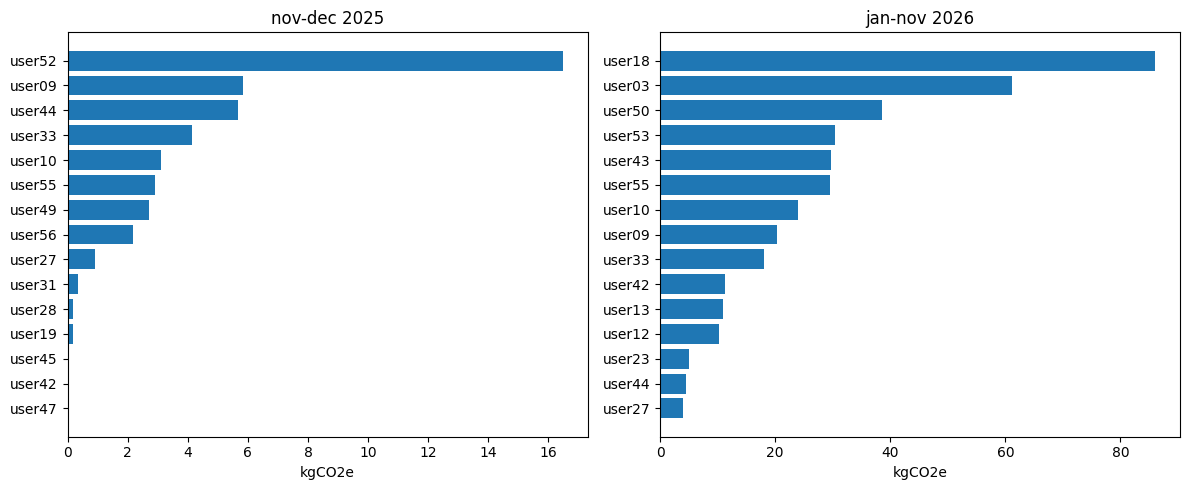

In [12]:
fig, axes = plt.subplots(1, len(repart), figsize=(12, 5))
for ax, (nom, u) in zip(axes, repart.items()):
    top = u.head(15)[::-1]
    ax.barh(top.index, top.kgCO2e)
    ax.set_title(nom)
    ax.set_xlabel("kgCO2e")
plt.tight_layout()
plt.show()

for nom, u in repart.items():
    u.round(2).to_csv(f"repartition_{nom.replace(' ', '_').replace('-', '_')}.csv")

## Statistiques générales

Utilisateurs actifs par mois.

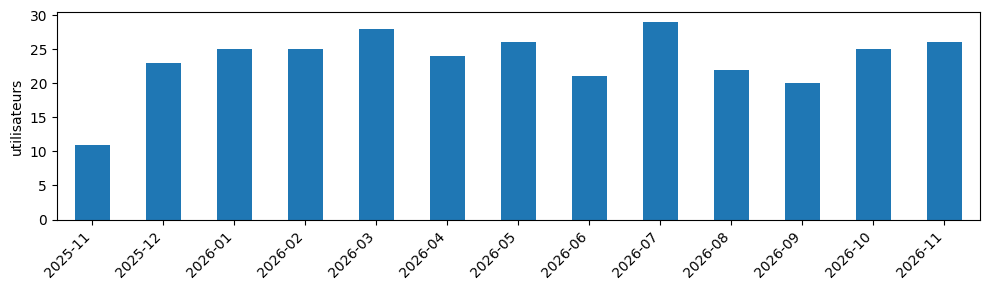

In [13]:
actifs = jobs.dropna(subset=["Start"]).groupby(jobs.Start.dt.to_period("M")).User.nunique()
ax = actifs.plot(kind="bar", figsize=(10, 3), color="C0")
ax.set_ylabel("utilisateurs")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Avant février 2026 il n'y avait pas de partition gpu et les GPU n'étaient pas dans l'accounting : aucun usage GPU visible pour nov-dec 2025.

In [14]:
for nom, u in repart.items():
    u = u[u.index != "compte_technique"]
    print(f"{nom} : {len(u)} utilisateurs, dont {(u.h_gpu > 0).sum()} sur GPU")

nov-dec 2025 : 22 utilisateurs, dont 0 sur GPU
jan-nov 2026 : 53 utilisateurs, dont 25 sur GPU


Part des heures en sessions JupyterHub et en jobs batch.

In [15]:
if "type" in jobs:
    for nom, (deb, fin) in PERIODES.items():
        d = heures(jobs, deb, fin)
        t = d.groupby("type")[["h_coeur", "h_gpu"]].sum()
        display(nom, (100 * t / t.sum()).round(1).rename(columns=lambda c: c + " %"))
else:
    print("pas de colonne JobName : relancer extraire_donnees_marbec_gpu.sh")

'nov-dec 2025'

,h_coeur %,h_gpu %
type,,
JupyterHub,64.3,NaN
batch,35.7,NaN


'jan-nov 2026'

,h_coeur %,h_gpu %
type,,
JupyterHub,44.8,10.2
batch,55.2,89.8


Efficacité CPU : heures coeur utilisées / heures coeur réservées.

In [16]:
for nom, (deb, fin) in PERIODES.items():
    d = heures(jobs, deb, fin)
    if d.empty:
        continue
    cle = ["Partition", "type"] if "type" in d else ["Partition"]
    e = d.groupby(cle)[["h_coeur", "h_cpu_reel"]].sum()
    e["efficacite_%"] = 100 * e.h_cpu_reel / e.h_coeur
    print(f"{nom} : efficacité globale {100 * d.h_cpu_reel.sum() / d.h_coeur.sum():.0f} %")
    display(e.round(1))

nov-dec 2025 : efficacité globale 26 %


h_coeur  h_cpu_reel  efficacite_%
Partition type                                         
standard  JupyterHub   5430.5       160.0           2.9
          batch        3009.2      2061.9          68.5

jan-nov 2026 : efficacité globale 26 %


h_coeur  h_cpu_reel  efficacite_%
Partition type                                          
cpu       JupyterHub  117104.7      4097.2           3.5
          batch        92145.6     47179.3          51.2
gpu       JupyterHub    4144.6       211.1           5.1
          batch        44890.4     13153.0          29.3
standard  JupyterHub    7794.2       306.2           3.9
          batch        22245.3      9545.9          42.9

Sessions JupyterHub : répartition de l'efficacité (CPU utilisé / CPU réservé) par session.

4140 sessions
efficacité <  1 % : 59 % des sessions, 66 % des heures réservées
efficacité <  5 % : 79 % des sessions, 79 % des heures réservées
efficacité < 20 % : 93 % des sessions, 96 % des heures réservées


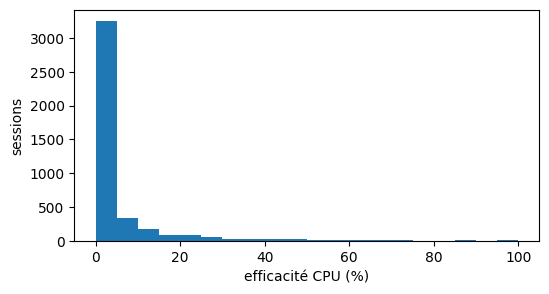

In [17]:
if "type" in jobs:
    s = jobs[(jobs.type == "JupyterHub") & (jobs.CPUTimeRAW > 0)]
    eff = 100 * s.cpu_reel_h * 3600 / s.CPUTimeRAW
    poids = s.CPUTimeRAW / s.CPUTimeRAW.sum()
    print(f"{len(s)} sessions")
    for seuil in [1, 5, 20]:
        print(f"efficacité < {seuil:2d} % : {100 * (eff < seuil).mean():.0f} % des sessions, "
              f"{100 * poids[eff < seuil].sum():.0f} % des heures réservées")
    ax = eff.clip(upper=100).plot(kind="hist", bins=20, figsize=(6, 3))
    ax.set_xlabel("efficacité CPU (%)")
    ax.set_ylabel("sessions")
    plt.show()

Heures coeur selon l'état final des jobs.

In [18]:
for nom, (deb, fin) in PERIODES.items():
    d = heures(jobs, deb, fin)
    t = d.groupby("etat").agg(jobs=("etat", "size"), h_coeur=("h_coeur", "sum"))
    t["jobs_%"] = 100 * t.jobs / t.jobs.sum()
    t["h_coeur_%"] = 100 * t.h_coeur / t.h_coeur.sum()
    display(nom, t.sort_values("jobs", ascending=False).round(1))

'nov-dec 2025'

,jobs,h_coeur,jobs_%,h_coeur_%
etat,,,,
CANCELLED,392,1775.3,34.4,21.0
COMPLETED,328,2226.1,28.8,26.4
FAILED,318,392.1,27.9,4.6
TIMEOUT,80,3968.0,7.0,47.0
OUT_OF_MEMORY,22,78.3,1.9,0.9


'jan-nov 2026'

,jobs,h_coeur,jobs_%,h_coeur_%
etat,,,,
COMPLETED,3003,108332.6,32.5,37.6
CANCELLED,2842,55962.2,30.7,19.4
FAILED,1927,9943.3,20.8,3.4
TIMEOUT,1296,104846.4,14.0,36.4
OUT_OF_MEMORY,170,8246.0,1.8,2.9
RUNNING,9,994.1,0.1,0.3


Taille et durée des jobs par partition.

In [19]:
d = jobs[jobs.ElapsedRaw > 0].assign(duree_h=lambda x: x.ElapsedRaw / 3600)
taille = d.groupby("Partition").agg(
    jobs=("AllocCPUS", "size"),
    coeurs_median=("AllocCPUS", "median"),
    coeurs_max=("AllocCPUS", "max"),
    duree_mediane_h=("duree_h", "median"),
    duree_p90_h=("duree_h", lambda x: x.quantile(0.9)),
)
taille.round(1)

,jobs,coeurs_median,coeurs_max,duree_mediane_h,duree_p90_h
Partition,,,,,
cpu,5605,2.0,32,0.5,24.0
gpu,2260,8.0,16,0.1,6.6
standard,2520,2.0,160,0.1,23.7


---
# marbec-data

NAS Synology RS2821RP+ et extension RX1217RP, 28 disques HAT5300-16T sans hibernation. Puissance estimée d'après les fiches Synology.

In [20]:
P_NAS_MESURE = None
p_nas = P_NAS_MESURE or (45 + 32 + 28 * 5)   # boîtiers + disques (4,2 W au repos, 8,4 W en activité)
VOLUME_TO = 113.4

for annee, h in HEURES.items():
    kwh, kg = emissions(p_nas, h)
    bilan[("marbec-data", annee)] = kg / 1000
    print(f"marbec-data {annee} : {p_nas:.0f} W, {kwh:,.0f} kWh, {kg / 1000:.2f} tCO2e")

marbec-data 2025 : 217 W, 2,319 kWh, 0.11 tCO2e
marbec-data 2026 (jusqu'au 25/11) : 217 W, 2,090 kWh, 0.10 tCO2e


Comparaison avec la méthode par volume stocké (Stockage_donnees.ipynb).

In [21]:
for to in [81.2, VOLUME_TO]:
    go = to * 1000
    print(f"{to} To : {go * 0.4 / 1000:.1f} tCO2e (0.4 kg/Go/an), "
          f"{go * 0.011 / 1000:.1f} à {go * 0.041 / 1000:.1f} tCO2e (Labos 1point5)")

81.2 To : 32.5 tCO2e (0.4 kg/Go/an), 0.9 à 3.3 tCO2e (Labos 1point5)
113.4 To : 45.4 tCO2e (0.4 kg/Go/an), 1.2 à 4.6 tCO2e (Labos 1point5)


---
# Résumé

tCO2e liées à l'électricité (usage), hors fabrication du matériel.

In [22]:
resume = pd.Series(bilan).unstack().round(2)
resume.loc["total"] = resume.sum()
resume

,2025,2026 (jusqu'au 25/11)
marbec-data,0.11,0.10
marbec-gpu,0.45,0.41
total,0.56,0.51
